# Mean Shift Clustering in Machine Learning

Mean Shift Clustering is an unsupervised machine learning algorithm used to group similar data points into clusters.

we will cover:
1. What is Mean Shift Clustering?
2. How Mean Shift works step by step.
3. Types and variations of Mean Shift.
4. Important parameters.
5. Complete ML project workflow.
6. Data visualization and preprocessing.
7. Five different Python coding examples.
8. Train/test splitting and evaluation.
9. Real-world use cases and practice assignments.

1. What is Mean Shift Clustering?

Mean Shift is an unsupervised clustering algorithm that identifies clusters by finding high-density regions (areas where many data points are concentrated).

Unlike K-Means, you do not need to specify the number of clusters before training.

For example, imagine an e-commerce company has customer information:
- Annual income
- Spending score
- Age

Mean Shift automatically identifies groups of customers with similar characteristics.

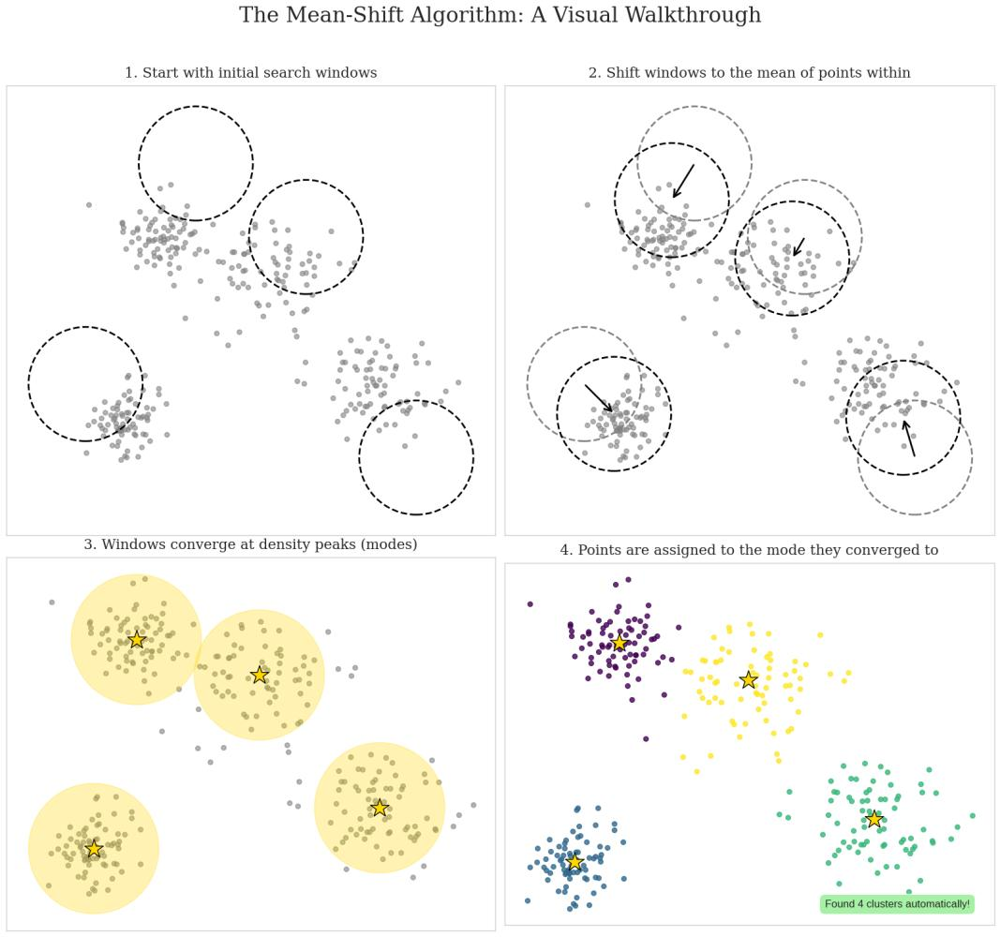

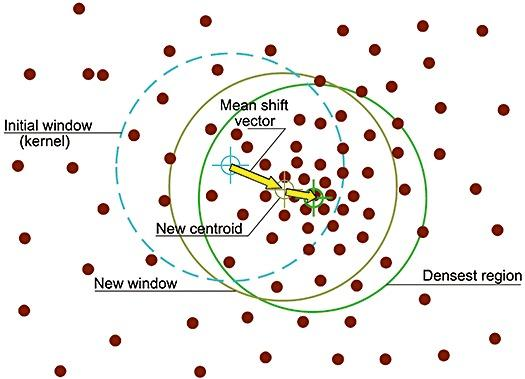

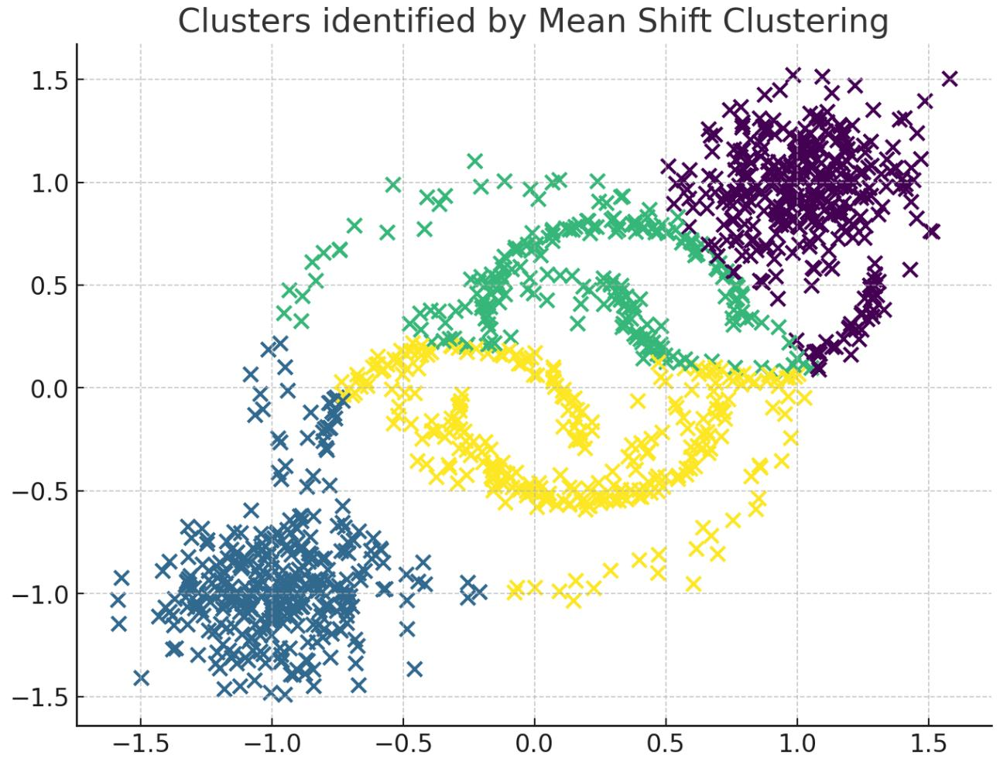

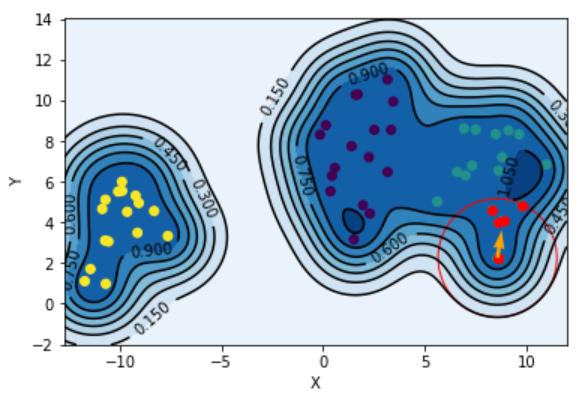

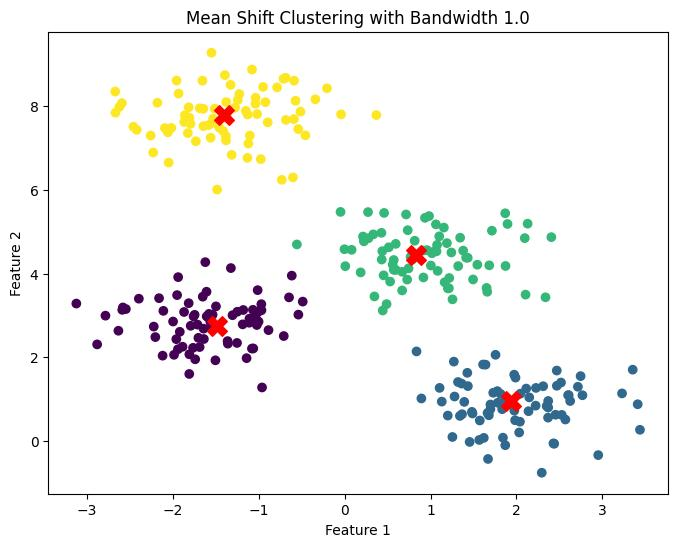

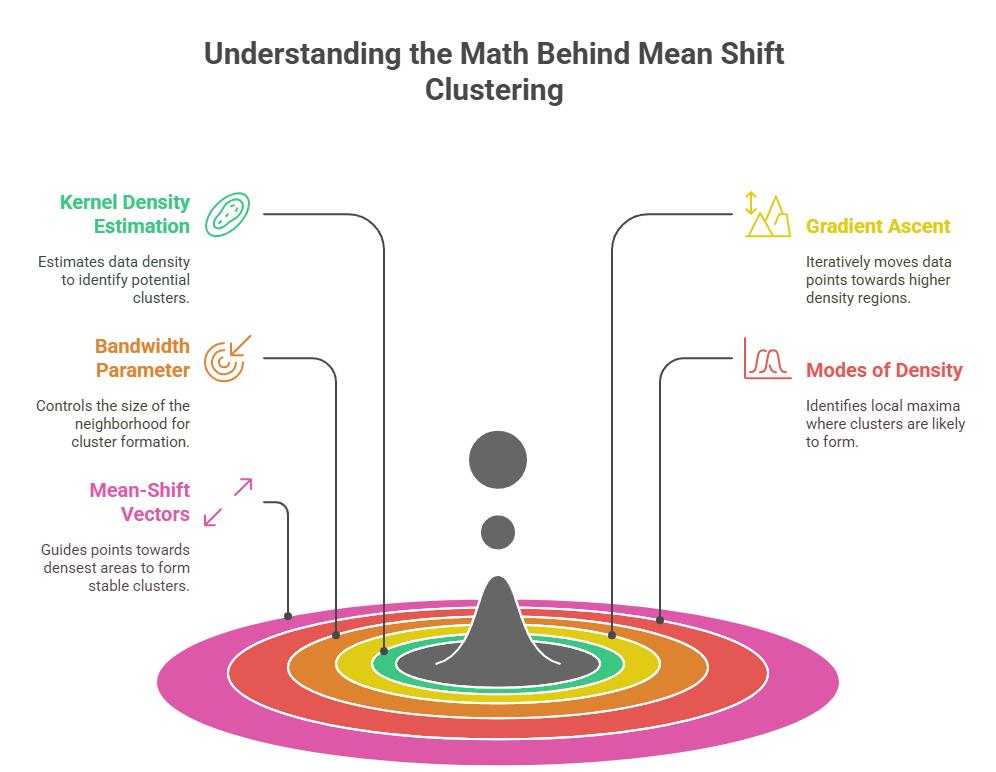

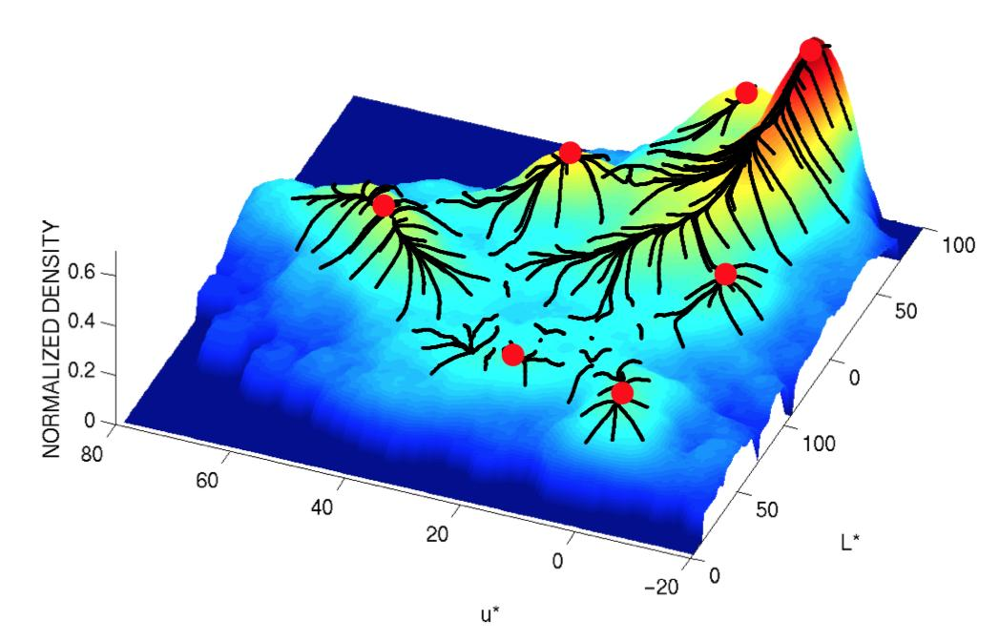

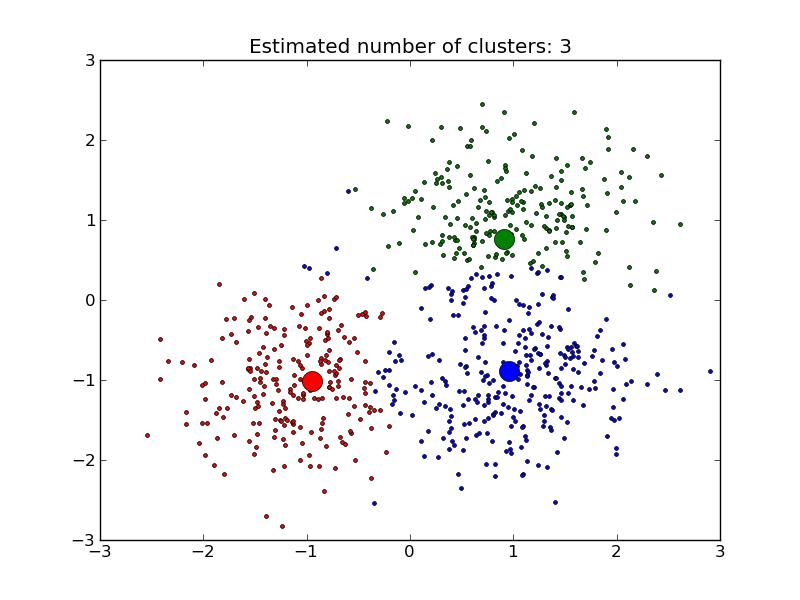

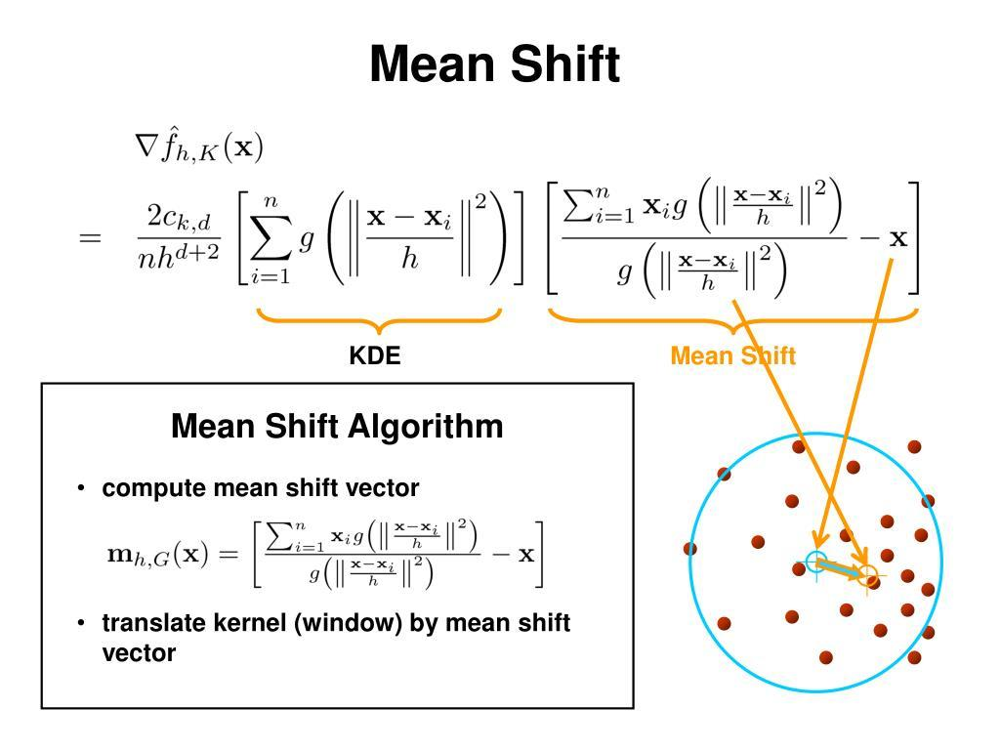

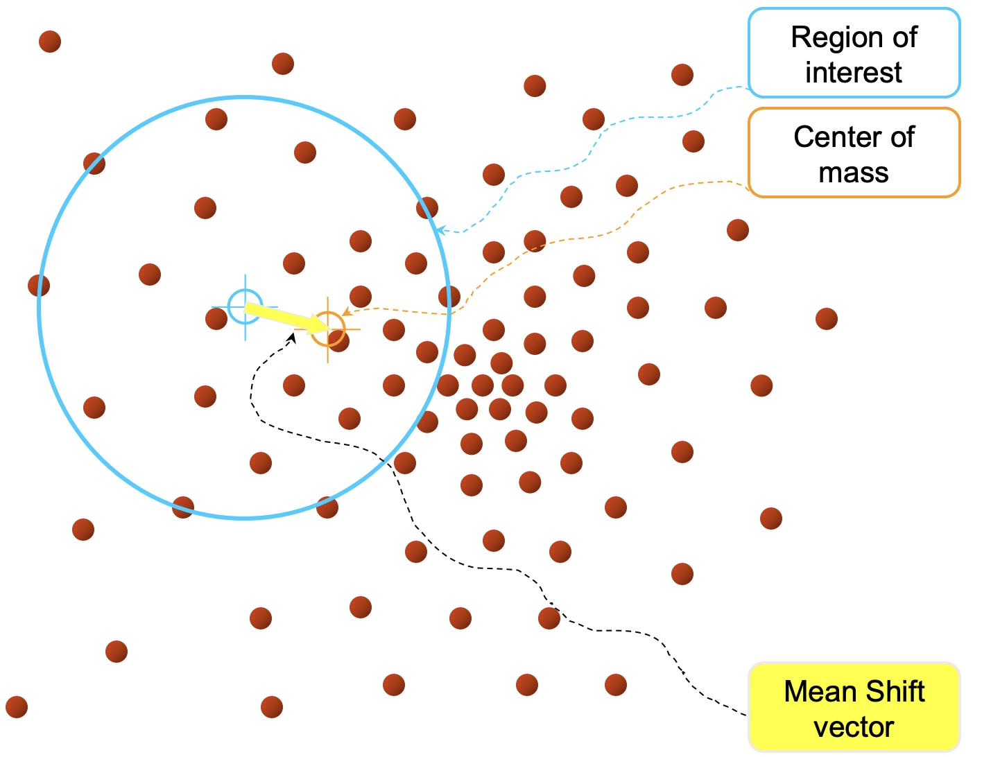

**Simple definition:** Mean Shift moves each data point toward the nearest high-density region until it reaches a cluster center.

2. How does Mean Shift work?

Mean Shift works through the following steps:

Mathematical formula

The Mean Shift update can be represented as:

3. Types and variations of Mean Shift

Mean Shift has different variations depending on the kernel function, bandwidth selection, and how the data is processed.

1. Gaussian Kernel Mean Shift

Uses Gaussian weights to give more importance to nearby data points and less importance to distant points.

Use case: Image segmentation and smooth density estimation.

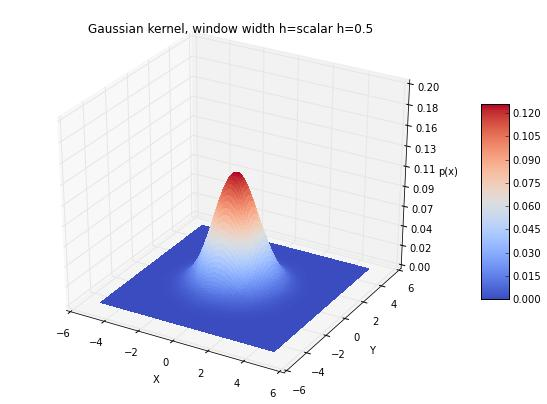

2. Flat / Uniform Kernel Mean Shift

Gives equal weight to all data points within the bandwidth.

Use case: Basic clustering and neighborhood-based density analysis.

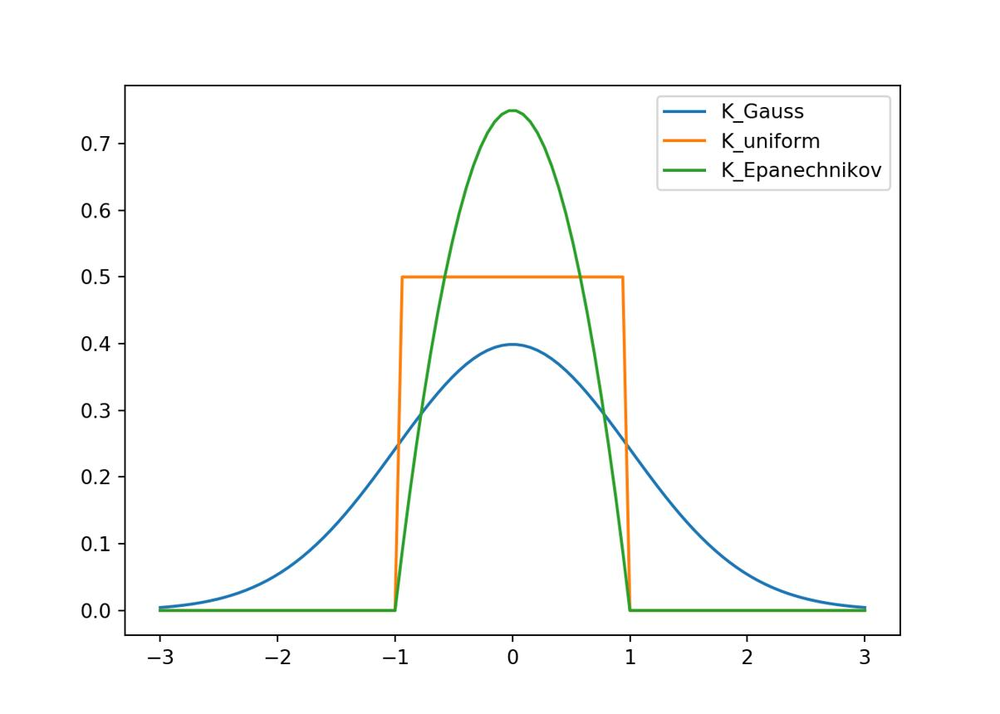

3. Adaptive Bandwidth Mean Shift

Uses different bandwidths in different regions depending on local data density.

Use case: Datasets with varying density.

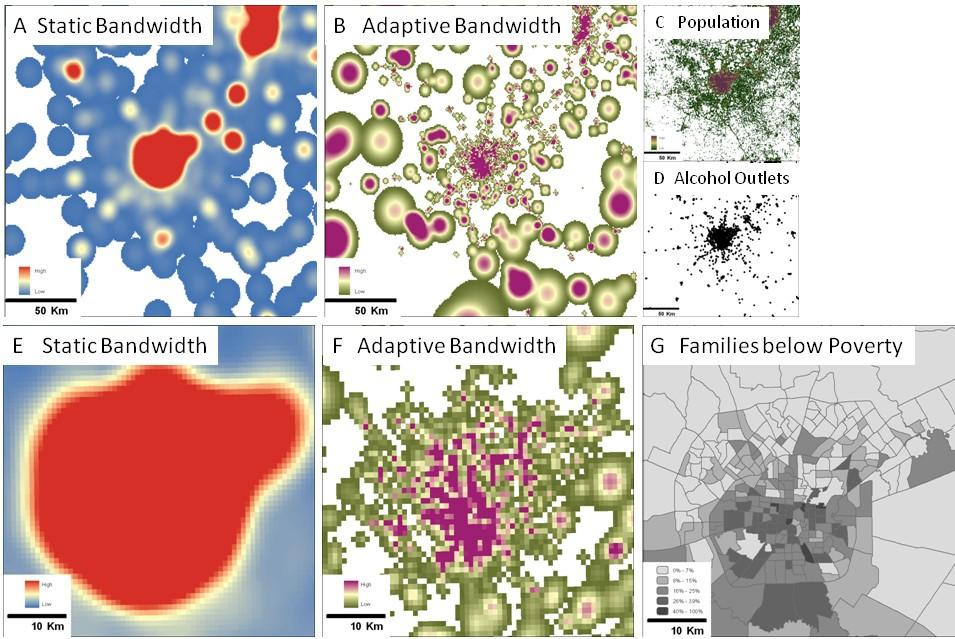

4. Multivariate Mean Shift

Works with multiple features simultaneously, such as age, income, spending score, and other numerical variables.

Use case: Customer segmentation and employee analytics.

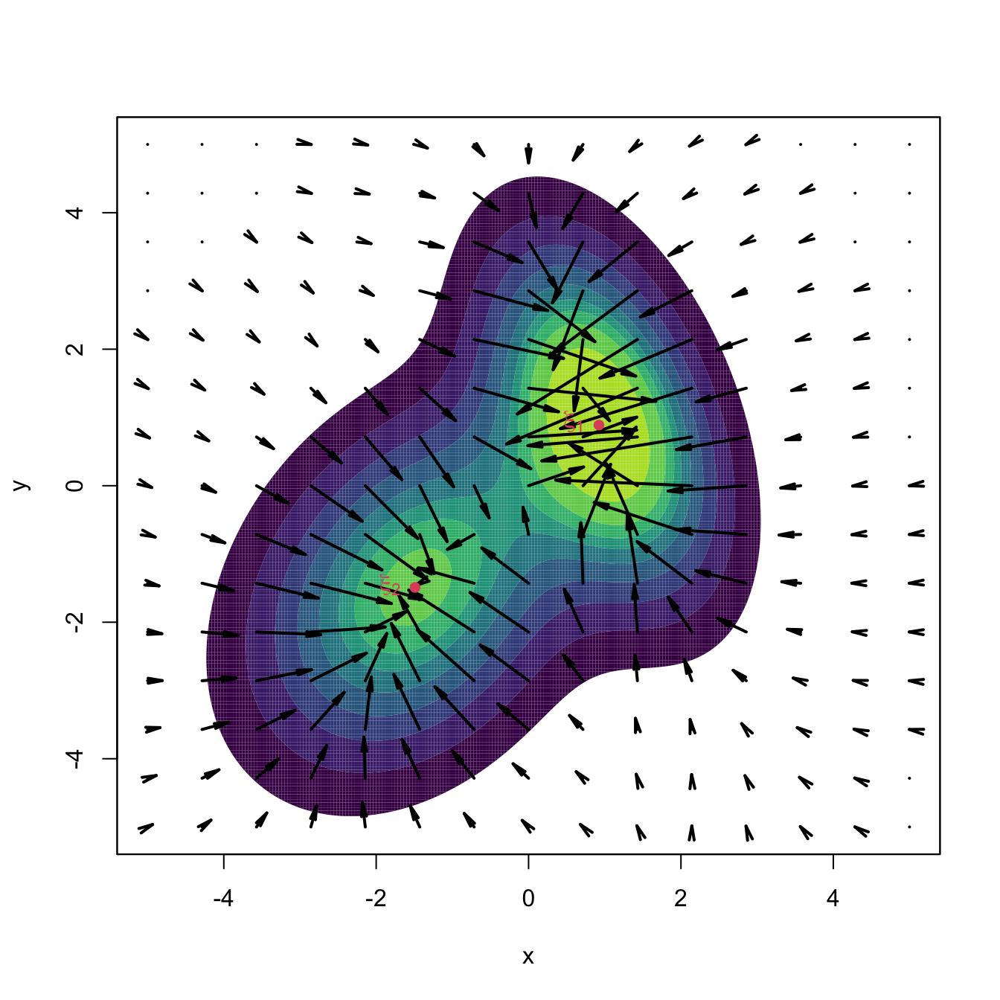

5. Spatial / Image Mean Shift

Uses pixel position and image characteristics to identify regions with similar colors and spatial properties.

Use case: Object segmentation and image processing.

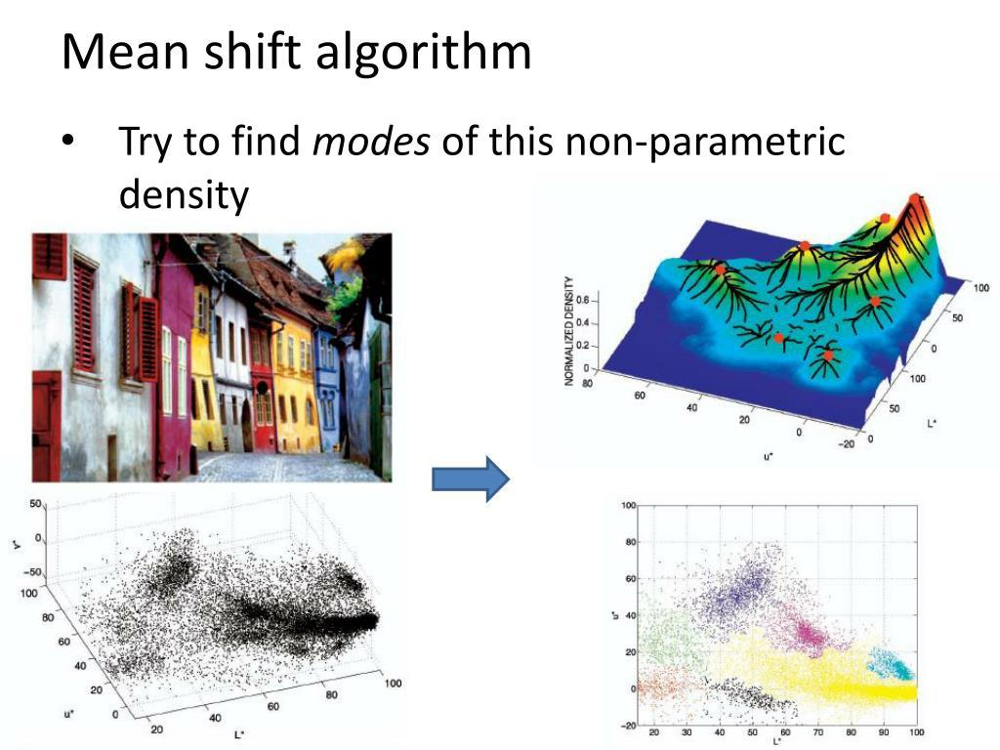

Important: These are common variations and application approaches, not five separate algorithms exposed by scikit-learn. Scikit-learn's MeanShift estimator uses a flat kernel and estimates cluster centers through iterative shifting.

4. Mean Shift important parameters in Python

We use:

|Parameter	|Purpose
:-----------|--------------------------
bandwidth|	Controls neighborhood size
bin_seeding|	Uses binned points as initial seeds
min_bin_freq|	Minimum frequency for a seed bin
cluster_all|	Assigns all points to clusters
max_iter|	Maximum iterations
n_jobs|	Number of parallel jobs

What is bandwidth?

Bandwidth is the most important parameter.

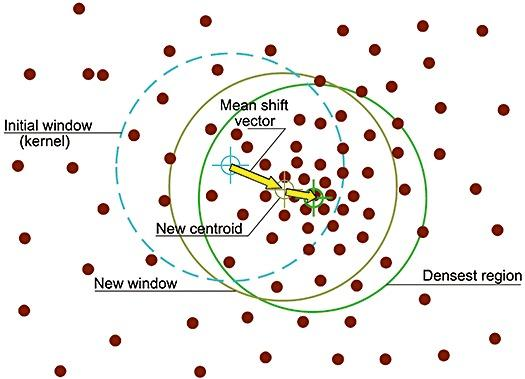
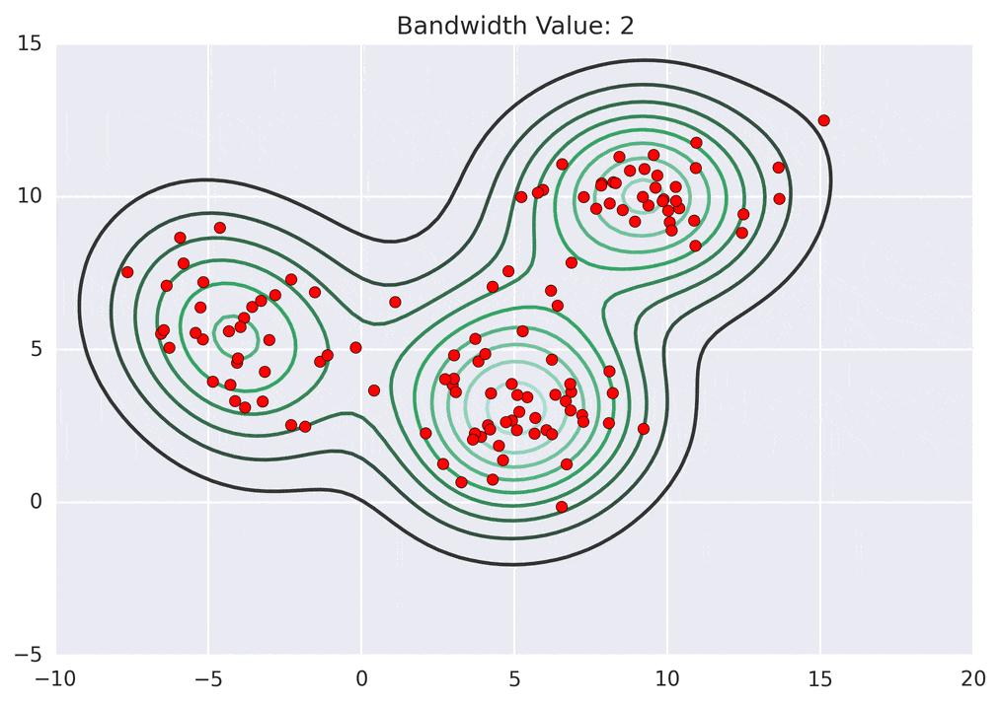

Small bandwidth
- More clusters.
- Detects smaller density regions.

Large bandwidth
- Fewer clusters.
- May combine different groups.

MeanShift(bandwidth=1.5)

A bandwidth of 1.5 is just an example. The appropriate value depends on the scale and distribution of your data.

5. Complete Mean Shift ML project workflow

This is the workflow you should follow when building a real-world Mean Shift clustering project.

Mean Shift ML Architecture

1. Problem Understanding
Define the business problem

2. Load Dataset
pandas, CSV, Excel, database

3. Understand Dataset
head, info, describe, shape

4. Data Cleaning
Missing values, duplicates, outliers

5. EDA
Understand data distribution and relationships

6. Data Visualization
Histograms, boxplots, scatterplots, heatmaps

7. Feature Engineering
Select useful numerical features

8. Feature Scaling
StandardScaler / MinMaxScaler

9. Train/Test Split
Separate data for evaluation

10. Mean Shift Model
Estimate bandwidth and train model

11. Predict Clusters
Assign cluster labels

12. Evaluation
Silhouette Score, Davies-Bouldin, Calinski-Harabasz

13. Cluster Interpretation
Understand each group's characteristics

14. Save Model
Joblib / Pickle

15. Deployment
Streamlit / Flask / FastAPI

Important difference from supervised ML: Mean Shift does not require a target variable (y). You can still split data into training and testing portions to check whether clusters learned from the training data generalize to unseen observations.

6. Python libraries required


Install these libraries in your VS Code terminal or Jupyter Notebook:

pip install numpy pandas matplotlib seaborn scikit-learn joblib

|Library	|Why we use it
:-----------|-----------------
NumPy|	Numerical calculations
Pandas|	Dataset handling
Matplotlib|	Data visualization
Seaborn|	Statistical visualization
Scikit-learn|	Mean Shift algorithm and preprocessing
Joblib|	Saving the trained model

7. Complete Python ML workflow – Customer Segmentation
Let's first build one complete project, from dataset creation to model evaluation.

- **Problem statement:** An e-commerce company wants to segment customers based on annual income, spending score, and age.

The objective is to identify customer groups automatically using Mean Shift.


## Step 1 – Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

Why?
- MeanShift: Performs clustering.
- estimate_bandwidth: Estimates the neighborhood radius.
- train_test_split: Separates training and testing data.
- StandardScaler: Scales features.
- PCA: Reduces dimensions for visualization

### Step 2 – Create dataset
We will create a sample customer dataset

In [2]:
from sklearn.datasets import make_blobs

X, _ = make_blobs(
    n_samples=500,
    centers=4,
    n_features=3,
    cluster_std=1.5,
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["Annual_Income", "Spending_Score", "Age"]
)

print(df.head())

   Annual_Income  Spending_Score        Age
0       1.198252      -10.997313   9.182066
1      -8.768673        5.283739   3.141681
2       3.889685       -6.381156  -8.002839
3      -3.010949        8.301868   3.659885
4       6.454154       -8.826556  10.205641


### Step 3 – Understand dataset

In [3]:
print("Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Shape: (500, 3)

First 5 Rows:
   Annual_Income  Spending_Score        Age
0       1.198252      -10.997313   9.182066
1      -8.768673        5.283739   3.141681
2       3.889685       -6.381156  -8.002839
3      -3.010949        8.301868   3.659885
4       6.454154       -8.826556  10.205641

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Annual_Income   500 non-null    float64
 1   Spending_Score  500 non-null    float64
 2   Age             500 non-null    float64
dtypes: float64(3)
memory usage: 11.8 KB

Statistical Summary:
       Annual_Income  Spending_Score         Age
count     500.000000      500.000000  500.000000
mean       -1.217597        0.132958    2.252750
std         5.115890        8.358891    6.136566
min       -13.111142      -12.537845  -10.925440
25%        -5.859086       -8.046535   -1.3456

Why?

Before applying ML, we need to understand:
- Number of rows and columns.
- Data types.
- Missing values.
- Duplicate records.
- Feature distributions.

### Step 4 – Data cleaning

In [4]:
# Remove duplicate rows
df = df.drop_duplicates()

# Handle missing numerical values
df = df.fillna(df.median(numeric_only=True))

print(df.isnull().sum())

Annual_Income     0
Spending_Score    0
Age               0
dtype: int64


### Step 5 – Exploratory Data Analysis (EDA)

A. Histograms

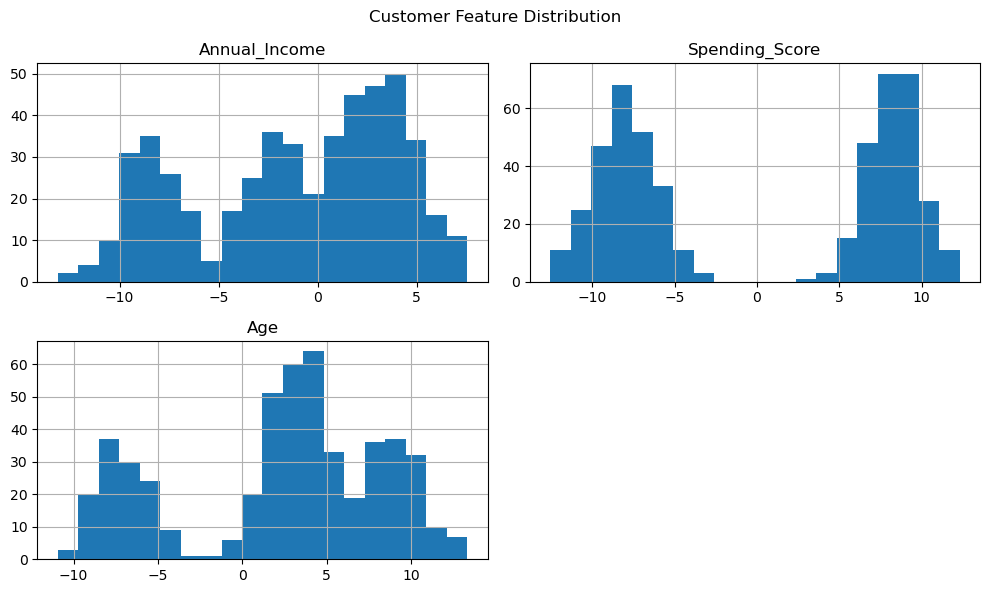

In [5]:
df.hist(figsize=(10, 6), bins=20)

plt.suptitle("Customer Feature Distribution")
plt.tight_layout()
plt.show()

Why? To understand the distribution of each feature.

B. Boxplots

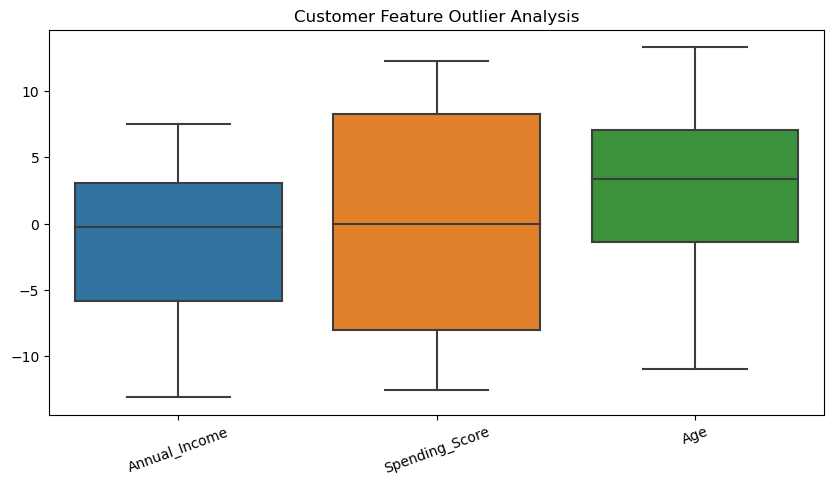

In [6]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df)

plt.title("Customer Feature Outlier Analysis")
plt.xticks(rotation=20)
plt.show()

Why? To identify potential outliers.

C. Correlation heatmap

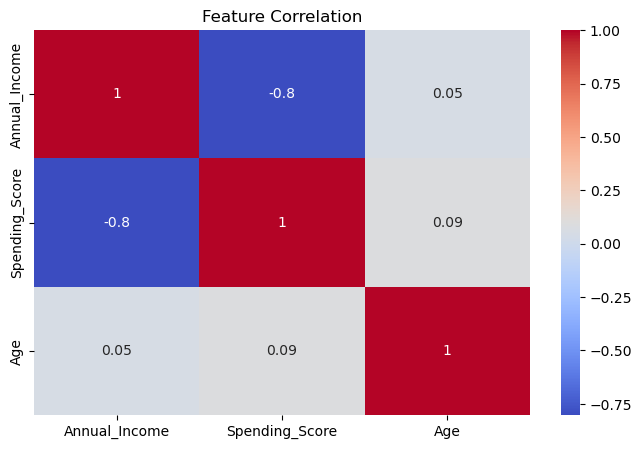

In [7]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation")
plt.show()

Why? To understand relationships between numerical features.

D. Scatterplot

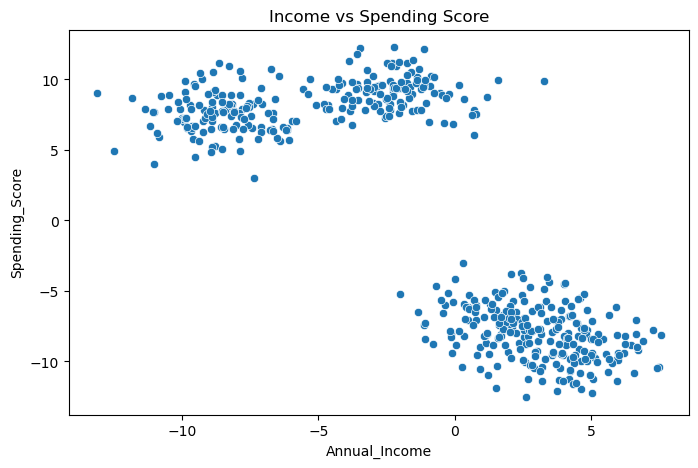

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score"
)

plt.title("Income vs Spending Score")
plt.show()

Step 6 – Feature selection

In [9]:
X = df[
    ["Annual_Income", "Spending_Score", "Age"]
]

print(X.head())

   Annual_Income  Spending_Score        Age
0       1.198252      -10.997313   9.182066
1      -8.768673        5.283739   3.141681
2       3.889685       -6.381156  -8.002839
3      -3.010949        8.301868   3.659885
4       6.454154       -8.826556  10.205641


We do not have a target column y because Mean Shift is an unsupervised algorithm.

### Step 7 – Train/Test split

In [10]:
X_train, X_test = train_test_split(
    X,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 3)
Testing data: (100, 3)


We use:
- 80% training data.
- 20% testing data.


Why? We want to check how well the learned cluster centers can assign unseen observations.

### Step 8 – Feature scaling

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

Why StandardScaler?

Mean Shift uses distances between points. Features with larger numerical ranges can dominate distance calculations.

StandardScaler transforms features approximately to:
\[
z = \frac{x-\mu}{\sigma}
\]

Always fit the scaler on training data only to avoid data leakage.

### Step 9 – Estimate bandwidth

In [12]:
bandwidth = estimate_bandwidth(
    X_train_scaled,
    quantile=0.2,
    n_samples=500
)

print("Estimated Bandwidth:", bandwidth)

Estimated Bandwidth: 0.713631725047263


Why?

Bandwidth determines the neighborhood size used to identify density peaks.

### Step 10 – Build Mean Shift model

In [13]:
model = MeanShift(
    bandwidth=bandwidth,
    bin_seeding=True,
    cluster_all=True
)

model.fit(X_train_scaled)

MeanShift(bandwidth=0.713631725047263, bin_seeding=True)

### Step 11 – Predict clusters

In [14]:
train_clusters = model.labels_

test_clusters = model.predict(X_test_scaled)

print("Training clusters:")
print(train_clusters[:20])

print("\nTesting clusters:")
print(test_clusters[:20])

print("\nNumber of clusters:")
print(len(np.unique(train_clusters)))

Training clusters:
[0 1 1 2 2 3 0 3 0 1 0 0 2 3 2 3 2 3 2 0]

Testing clusters:
[1 2 1 2 3 0 3 3 1 0 3 1 2 0 3 2 1 1 1 2]

Number of clusters:
4


Here:
- labels_ gives training cluster assignments.
- predict() assigns unseen testing points to their nearest learned cluster center.

Step 12 – Model evaluation

Clustering has no actual target labels, so we use internal evaluation metrics.

In [15]:
if len(np.unique(train_clusters)) > 1:
    silhouette = silhouette_score(
        X_train_scaled,
        train_clusters
    )

    db_score = davies_bouldin_score(
        X_train_scaled,
        train_clusters
    )

    ch_score = calinski_harabasz_score(
        X_train_scaled,
        train_clusters
    )

    print("Silhouette Score:", silhouette)
    print("Davies Bouldin Score:", db_score)
    print("Calinski Harabasz Score:", ch_score)
else:
    print("Only one cluster found. Metrics cannot be calculated.")

Silhouette Score: 0.6847717465852449
Davies Bouldin Score: 0.43646576833130624
Calinski Harabasz Score: 2062.9334009803883


|Metric|	Good result
:------|----------------
Silhouette Score|	Closer to +1
Davies-Bouldin|	Lower
Calinski-Harabasz|	Higher

These metrics measure cluster separation and compactness, not prediction accuracy.

Step 13 – Visualize clusters

We have three features, so we use PCA to display them in two dimensions.

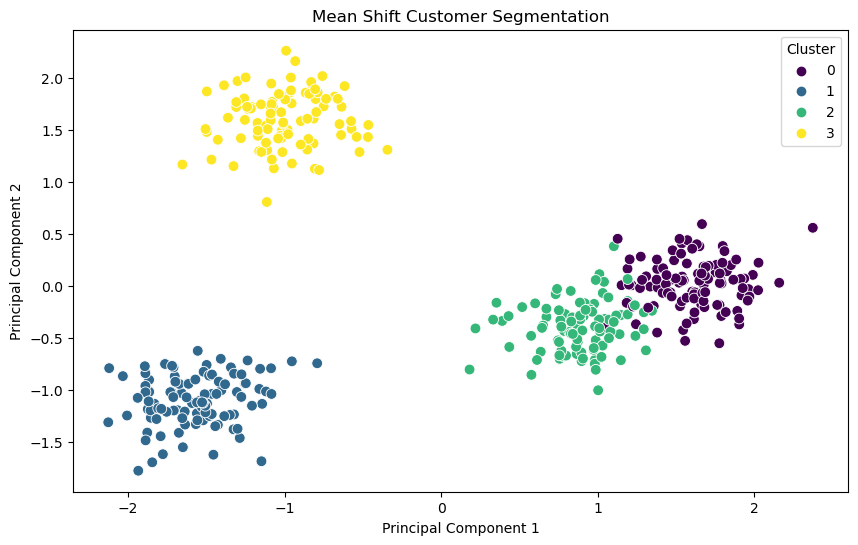

In [16]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=train_clusters,
    palette="viridis",
    s=60
)

plt.title("Mean Shift Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

### Step 14 – Understand cluster profiles

In [17]:
result = X_train.copy()

result["Cluster"] = train_clusters

print(
    result.groupby("Cluster").mean().round(2)
)

print("\nNumber of customers in each cluster:")

print(result["Cluster"].value_counts().sort_index())

         Annual_Income  Spending_Score   Age
Cluster                                     
0                -8.57            7.49  2.42
1                 4.18           -9.15  9.39
2                -2.27            9.05  4.36
3                 1.88           -6.82 -6.96

Number of customers in each cluster:
Cluster
0    106
1    103
2     97
3     94
Name: count, dtype: int64


This helps us understand the characteristics of each customer group.

### Step 15 – Save the model

In [18]:
joblib.dump(
    {
        "model": model,
        "scaler": scaler
    },
    "mean_shift_customer_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


### Step 16 – Predict a new customer

In [19]:
saved = joblib.load("mean_shift_customer_model.pkl")

new_customer = pd.DataFrame(
    [[45, 70, 30]],
    columns=[
        "Annual_Income",
        "Spending_Score",
        "Age"
    ]
)

new_scaled = saved["scaler"].transform(new_customer)

prediction = saved["model"].predict(new_scaled)

print("Customer belongs to cluster:", prediction[0])

Customer belongs to cluster: 2


This completes your first end-to-end Mean Shift project.

8. Five different Mean Shift Python examples

Now let's practice five real-world use cases.

|Example	|Problem statement	|Features
:-----------|-------------------|------------
Customer segmentation |	Group customers by purchasing behavior	|Income, spending, age
Student performance   |	Group students by academic performance	|Study hours, attendance, marks
Employee analytics    |	Group employees by work performance	|Experience, working hours, performance
E-commerce products   |	Group similar products	|Price, rating, sales, reviews
Image segmentation    |	Identify similar image regions	|Pixel position, RGB values

The first example is the complete customer project explained above. The following code gives you a reusable workflow for all five examples.

**Common reusable ML function**

Instead of writing the same preprocessing, training, evaluation, and visualization code five times, we will create one function.

In [20]:
def mean_shift_project(df, feature_cols, project_name):

    print("\n" + "=" * 55)
    print(project_name)
    print("=" * 55)

    # 1. Select features
    X = df[feature_cols].copy()

    # 2. Train test split
    X_train, X_test = train_test_split(
        X,
        test_size=0.20,
        random_state=42
    )

    # 3. Scaling
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # 4. Estimate bandwidth
    bandwidth = estimate_bandwidth(
        X_train_scaled,
        quantile=0.2,
        n_samples=min(500, len(X_train_scaled))
    )

    # Prevent zero bandwidth
    if not np.isfinite(bandwidth) or bandwidth <= 0:
        bandwidth = 1.0

    print("Bandwidth:", bandwidth)

    # 5. Build model
    model = MeanShift(
        bandwidth=bandwidth,
        bin_seeding=True,
        cluster_all=True
    )

    # 6. Train model
    model.fit(X_train_scaled)

    # 7. Predict clusters
    train_labels = model.labels_
    test_labels = model.predict(X_test_scaled)

    print("Number of clusters:",
          len(np.unique(train_labels)))

    # 8. Evaluation
    if len(np.unique(train_labels)) > 1:
        print(
            "Silhouette Score:",
            silhouette_score(X_train_scaled, train_labels)
        )

        print(
            "Davies Bouldin Score:",
            davies_bouldin_score(X_train_scaled, train_labels)
        )

        print(
            "Calinski Harabasz Score:",
            calinski_harabasz_score(X_train_scaled, train_labels)
        )
    else:
        print("Only one cluster found.")

    # 9. Cluster profile
    result = X_train.copy()
    result["Cluster"] = train_labels

    print("\nCluster Profiles:")
    print(result.groupby("Cluster").mean().round(2))

    # 10. Visualization using PCA
    pca = PCA(n_components=2)

    X_pca = pca.fit_transform(X_train_scaled)

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        x=X_pca[:, 0],
        y=X_pca[:, 1],
        hue=train_labels,
        palette="viridis",
        s=50
    )

    plt.title(project_name)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.show()

    return model, scaler, result, test_labels

Why create a function?
- Avoid repeating code.
- Reuse the same ML workflow.
- Compare different datasets.
- Make projects easier to maintain.

### Example 1 – Retail Customer Segmentation

**Problem statement:** A retail company wants to identify customer groups based on income, spending score, and age.


Retail Customer Segmentation
Bandwidth: 0.713631725047263
Number of clusters: 4
Silhouette Score: 0.6847717465852449
Davies Bouldin Score: 0.43646576833130624
Calinski Harabasz Score: 2062.9334009803883

Cluster Profiles:
         Annual_Income  Spending_Score   Age
Cluster                                     
0                -8.57            7.49  2.42
1                 4.18           -9.15  9.39
2                -2.27            9.05  4.36
3                 1.88           -6.82 -6.96


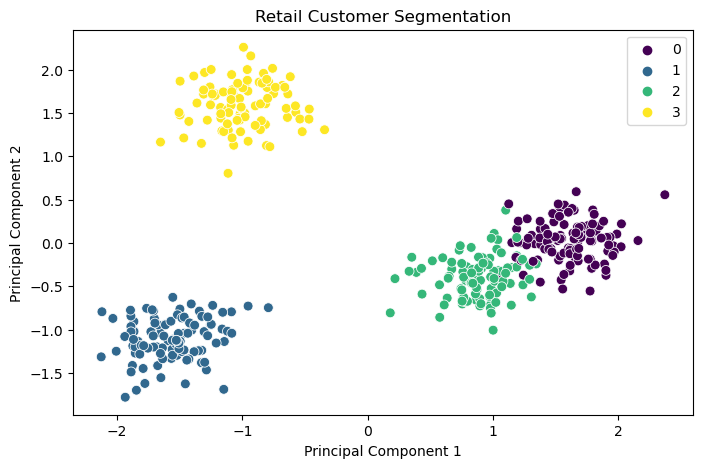

In [21]:
from sklearn.datasets import make_blobs

X1, _ = make_blobs(
    n_samples=500,
    centers=4,
    n_features=3,
    random_state=42,
    cluster_std=1.5
)

customer_df = pd.DataFrame(
    X1,
    columns=[
        "Annual_Income",
        "Spending_Score",
        "Age"
    ]
)

model1, scaler1, result1, test1 = mean_shift_project(
    customer_df,
    [
        "Annual_Income",
        "Spending_Score",
        "Age"
    ],
    "Retail Customer Segmentation"
)

#### Business interpretation:

|Possible cluster|	Business interpretation
:--------|--------------------------------
Cluster 0|	High-income customers
Cluster 1|	Low-income customers
Cluster 2|	High-spending customers
Cluster 3|	Moderate-spending customers

These are possible interpretations only. Always use the actual cluster profile to assign business meanings.

Use case: Targeted marketing, customer retention, personalized offers.

### Example 2 – Student Performance Clustering

Problem statement: A college wants to group students according to study hours, attendance, and examination marks.


Student Performance Clustering
Bandwidth: 0.8846935639218099
Number of clusters: 3
Silhouette Score: 0.667479360792131
Davies Bouldin Score: 0.4810539177655939
Calinski Harabasz Score: 957.6479000789212

Cluster Profiles:
         Study_Hours  Attendance  Exam_Marks
Cluster                                     
0              -2.27        0.49        3.30
1               6.24       -9.46        3.71
2               1.61        8.14        8.23


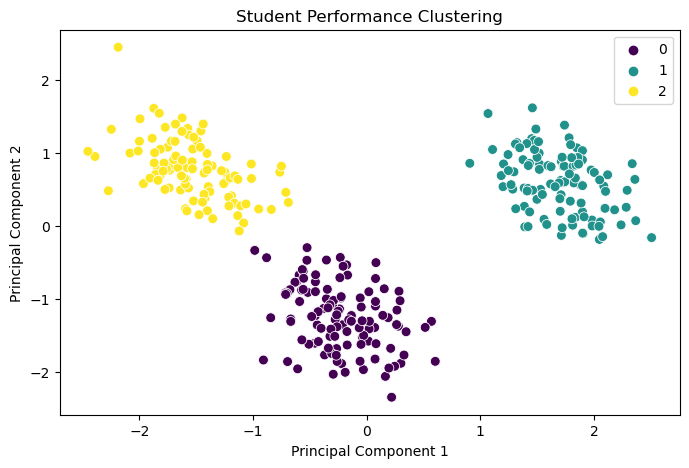

In [22]:
X2, _ = make_blobs(
    n_samples=400,
    centers=3,
    n_features=3,
    random_state=20,
    cluster_std=1.3
)

student_df = pd.DataFrame(
    X2,
    columns=[
        "Study_Hours",
        "Attendance",
        "Exam_Marks"
    ]
)

model2, scaler2, result2, test2 = mean_shift_project(
    student_df,
    [
        "Study_Hours",
        "Attendance",
        "Exam_Marks"
    ],
    "Student Performance Clustering"
)

What do we learn?
- Which students have similar academic performance?
- Which groups may need additional academic support?
- Which students have strong attendance and examination performance?

Use case: Student performance analysis and academic support planning.

### Example 3 – Employee Analytics

Problem statement: An organization wants to group employees based on experience, working hours, and performance ratings.


Employee Analytics
Bandwidth: 0.9209298239789626
Number of clusters: 3
Silhouette Score: 0.5104940072627208
Davies Bouldin Score: 0.7344745935109378
Calinski Harabasz Score: 781.0948494303884

Cluster Profiles:
         Experience  Working_Hours  Performance
Cluster                                        
0              0.47          -4.86         2.09
1              9.86          -4.93         1.78
2             -6.73           9.30        -3.27


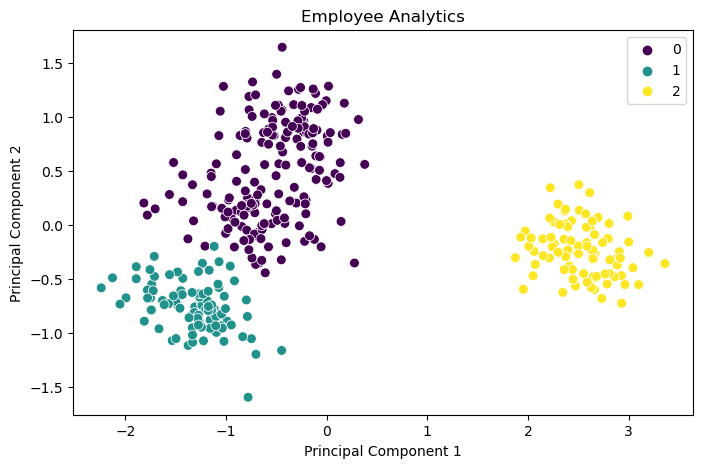

In [23]:
X3, _ = make_blobs(
    n_samples=450,
    centers=4,
    n_features=3,
    random_state=30,
    cluster_std=1.4
)

employee_df = pd.DataFrame(
    X3,
    columns=[
        "Experience",
        "Working_Hours",
        "Performance"
    ]
)

model3, scaler3, result3, test3 = mean_shift_project(
    employee_df,
    [
        "Experience",
        "Working_Hours",
        "Performance"
    ],
    "Employee Analytics"
)

What do we learn?

- Employees with similar experience.
- Employees with similar working hours.
- Employees with similar performance ratings.

Use case: Workforce planning, employee development, training recommendations.

### Example 4 – E-commerce Product Clustering

Problem statement: An online shopping company wants to group similar products based on price, ratings, sales, and reviews.


E-commerce Product Clustering
Bandwidth: 0.9867784039558538
Number of clusters: 4
Silhouette Score: 0.650940576367885
Davies Bouldin Score: 0.5066620460125341
Calinski Harabasz Score: 1350.1084713669818

Cluster Profiles:
         Price  Rating  Sales  Reviews
Cluster                               
0         6.20    4.22  -9.64     8.19
1        -0.82   -3.62   0.67     2.43
2         5.50    3.71   9.82     2.49
3        -1.60   -8.74   5.62    -4.30


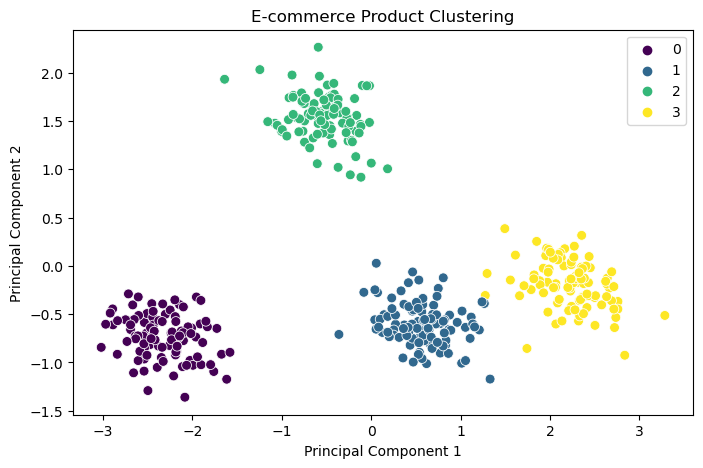

In [24]:
X4, _ = make_blobs(
    n_samples=500,
    centers=4,
    n_features=4,
    random_state=40,
    cluster_std=1.5
)

product_df = pd.DataFrame(
    X4,
    columns=[
        "Price",
        "Rating",
        "Sales",
        "Reviews"
    ]
)

model4, scaler4, result4, test4 = mean_shift_project(
    product_df,
    [
        "Price",
        "Rating",
        "Sales",
        "Reviews"
    ],
    "E-commerce Product Clustering"
)

What do we learn?
- Similar products.
- Products with similar customer ratings.
- Products with similar sales performance.
- Products that may need marketing attention.

Use case: Product recommendation, inventory planning, product category analysis.

## Example 5 – Image Segmentation Using Mean Shift

**Problem statement:** Separate different regions of an image based on their pixel colors and positions.

We will generate a small sample image ourselves, so you do not need an external image dataset.

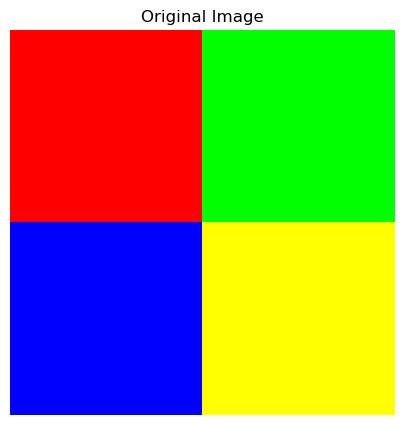


Image Segmentation
Bandwidth: 1.2720787269129437
Number of clusters: 4
Silhouette Score: 0.7014071199384454
Davies Bouldin Score: 0.4526934006740477
Calinski Harabasz Score: 2162.577698113086

Cluster Profiles:
         X_Position  Y_Position  Red  Green  Blue
Cluster                                          
0              0.23        0.75  0.0    0.0   1.0
1              0.73        0.72  1.0    1.0   0.0
2              0.24        0.23  1.0    0.0   0.0
3              0.73        0.23  0.0    1.0   0.0


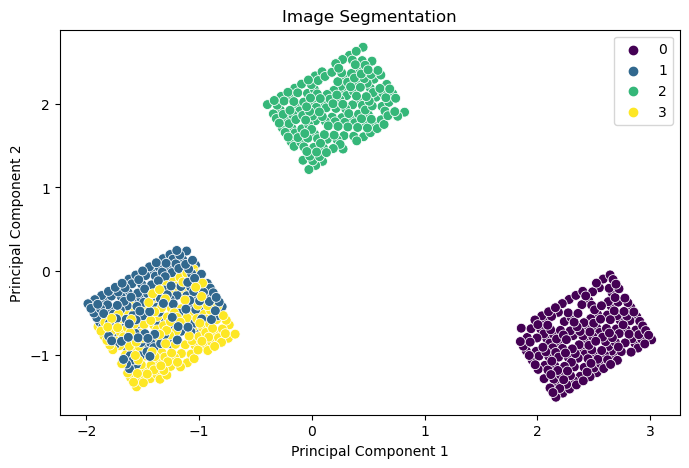

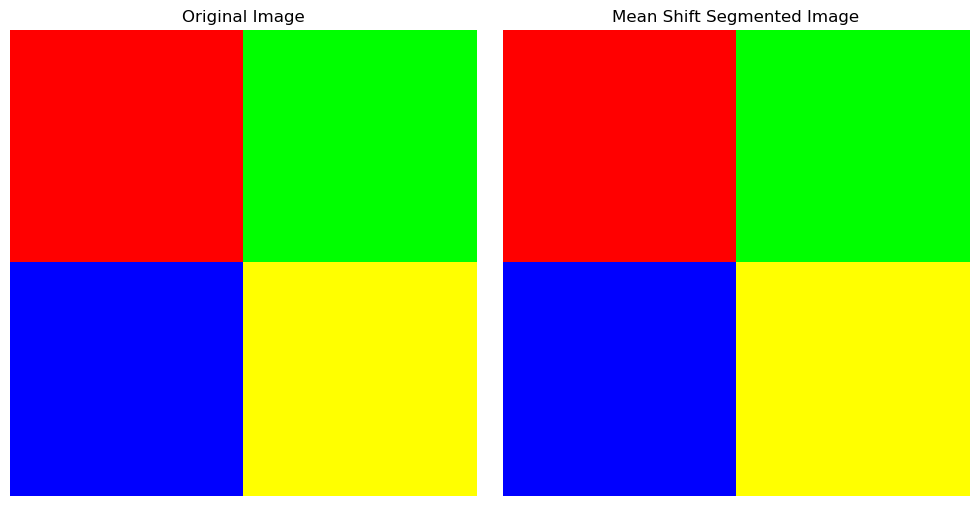

Image clusters: 4


In [25]:
# Create a sample RGB image
height, width = 30, 30

image = np.zeros((height, width, 3))

# Region 1: Red
image[:15, :15] = [255, 0, 0]

# Region 2: Green
image[:15, 15:] = [0, 255, 0]

# Region 3: Blue
image[15:, :15] = [0, 0, 255]

# Region 4: Yellow
image[15:, 15:] = [255, 255, 0]

# Display original image
plt.figure(figsize=(5, 5))
plt.imshow(image.astype(np.uint8))
plt.title("Original Image")
plt.axis("off")
plt.show()

# Generate pixel coordinates
y, x = np.mgrid[0:height, 0:width]

# Normalize pixel positions
x = x / width
y = y / height

# Normalize RGB values
rgb = image / 255.0

# Combine position and color features
pixels = np.column_stack([
    x.ravel(),
    y.ravel(),
    rgb.reshape(-1, 3)
])

image_df = pd.DataFrame(
    pixels,
    columns=[
        "X_Position",
        "Y_Position",
        "Red",
        "Green",
        "Blue"
    ]
)

# Apply Mean Shift workflow
model5, scaler5, result5, test5 = mean_shift_project(
    image_df,
    [
        "X_Position",
        "Y_Position",
        "Red",
        "Green",
        "Blue"
    ],
    "Image Segmentation"
)

# Segment the complete image using the trained model
all_scaled = scaler5.transform(image_df)

all_labels = model5.predict(all_scaled)

segmented = np.zeros_like(image)

for cluster in np.unique(all_labels):

    mask = all_labels == cluster

    # Replace pixels with average RGB color
    average_color = rgb.reshape(-1, 3)[mask].mean(axis=0)

    segmented.reshape(-1, 3)[mask] = average_color

# Display segmented image
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image.astype(np.uint8))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.clip(segmented * 255, 0, 255).astype(np.uint8))
plt.title("Mean Shift Segmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image clusters:", len(np.unique(all_labels)))

What are we doing here?


1. Creating a sample RGB image.
2. Extracting pixel positions.
3. Extracting red, green, and blue values.
4. Combining these into five numerical features.
5. Applying Mean Shift clustering.
6. Replacing each pixel with its cluster's average color.


Use case: Image segmentation, object detection preprocessing, medical image analysis, and computer vision.

Note: This is a synthetic four-region image to demonstrate the technique, not a real-world image segmentation benchmark.

### 9. How to choose the best bandwidth?
Bandwidth directly affects the number of clusters.

Instead of selecting only one bandwidth, experiment with multiple values.

In [26]:
bandwidth_values = [0.5, 1.0, 1.5, 2.0, 2.5]

for bw in bandwidth_values:

    model = MeanShift(
        bandwidth=bw,
        bin_seeding=True
    )

    model.fit(X_train_scaled)

    labels = model.labels_

    n_clusters = len(np.unique(labels))

    print("\nBandwidth:", bw)
    print("Clusters:", n_clusters)

    if n_clusters > 1 and n_clusters < len(labels):

        score = silhouette_score(
            X_train_scaled,
            labels
        )

        print("Silhouette Score:", score)


Bandwidth: 0.5
Clusters: 6
Silhouette Score: 0.5813029567437908

Bandwidth: 1.0
Clusters: 3
Silhouette Score: 0.7317617410572432

Bandwidth: 1.5
Clusters: 3
Silhouette Score: 0.7317617410572432

Bandwidth: 2.0
Clusters: 2
Silhouette Score: 0.5647468156384844

Bandwidth: 2.5
Clusters: 1


How to interpret the results:

- Too many clusters: bandwidth may be too small.
- Too few clusters: bandwidth may be too large.
- Higher silhouette score: generally better separation and cohesion.

Do not choose bandwidth using silhouette score alone. Also examine cluster sizes, business usefulness, and stability.

10. Mean Shift vs K-Means vs DBSCAN vs Hierarchical Clustering

Since you are studying different clustering algorithms, this comparison will help you understand when to use each one.

|Feature	|Mean Shift	|K-Means	|DBSCAN	|Hierarchical
:-----------|-----------|-----------|-------|-------------
Learning|	Unsupervised|	Unsupervised|	Unsupervised|	Unsupervised
Number of clusters|	Automatic	|Predefined K	|Automatic	|Chosen by cutting tree
Main parameter|	Bandwidth	|K	|Epsilon, min_samples	|Linkage, distance
Detects noise|	Limited support	|No	|Yes	|No standard noise label
Cluster shapes|	Density-based	|Mostly spherical	|Arbitrary shapes	|Depends on linkage
Scaling needed|	Yes	|Yes	|Yes	|Usually yes
Large datasets|	Can be expensive	|Efficient	|Can be expensive	|Can be expensive

11. Advantages and disadvantages

* Advantages
1. Does not require predefined cluster count.
2. Can identify clusters with different shapes.
3. Finds density peaks automatically.
4. Useful for image segmentation.
5. Can work with multidimensional numerical data.
* Disadvantages
1. Computationally expensive on large datasets.
2. Bandwidth selection is important.
3. Can struggle with clusters having very different densities.
4. Sensitive to feature scaling.
5. High-dimensional data can make density estimation difficult.

12. Practice assignments

Now try these five assignments independently to strengthen your ML skills.

No.|	Assignment	|Your task
:--|----------------|----------
1|	Customer segmentation	|Compare bandwidth 0.5, 1.0, 1.5 and 2.0
2|	Student analytics	|Identify student groups and interpret cluster profiles
3|	Employee analytics	|Compare Mean Shift and K-Means
4|	E-commerce analytics	|Identify product groups and evaluate their sizes
5|	Image segmentation	|Try Mean Shift on your own JPG image

For each assignment, complete these steps:

- [ ] Load or generate the dataset.
- [ ] Understand the dataset.
- [ ] Perform data cleaning.
- [ ] Perform EDA.
- [ ] Create 3–4 visualizations.
- [ ] Select useful features.
- [ ] Split training and testing data.
- [ ] Apply feature scaling.
- [ ] Estimate bandwidth.
- [ ] Train Mean Shift.
- [ ] Predict cluster labels.
- [ ] Evaluate using clustering metrics.
- [ ] Visualize the clusters.
- [ ] Interpret the results.
- [ ] Save the model.

### 13. Important interview questions


1. What is Mean Shift Clustering?
2. Is Mean Shift supervised or unsupervised?
3. Why don't we need to specify K in Mean Shift?
4. What is bandwidth?
5. What happens when bandwidth is too small?
6. What happens when bandwidth is too large?
7. What is the difference between Mean Shift and K-Means?
8. Why is StandardScaler important?
9. What is a kernel function?
10. What is the Silhouette Score?
11. Can Mean Shift identify noise?
12. What are the limitations of Mean Shift?
13. Can Mean Shift be used for image segmentation?
14. Why do we use PCA for visualization?
15. How can we deploy a Mean Shift model?

14. Recommended learning sequence

You have now covered several important unsupervised clustering algorithms. I recommend studying them in this order:

Unsupervised Machine Learning Roadmap

1. K-Means Clustering
   * Core concept
   * Centroid-based clustering.
2. Hierarchical Clustering
   
   * Agglomerative and divisive clustering, dendrograms.
3. DBSCAN
   
   * Density-based clustering and noise detection.
4. Mean Shift
   
   * Density peaks and automatic cluster discovery.
5. Gaussian Mixture Models (GMM)
   
   * Probabilistic clustering and soft assignments.
6. OPTICS
   
   * Density-based clustering with varying density.
7. Spectral Clustering
   
   * Graph-based clustering.

My recommendation: After completing these five Mean Shift examples, build one comparison project using K-Means, DBSCAN, Hierarchical Clustering, and Mean Shift on the same customer dataset. Compare their cluster counts, Silhouette Scores, Davies-Bouldin Scores, and visualizations. This will give you practical experience in selecting the right clustering algorithm for a real ML project.